# Section 1: Live Data Collection
This section fetches real-time cyber security news from GNews and Guardian APIs to build the dataset for analysis.

## Import Required Libraries
We import the libraries needed to fetch and store live news data.

In [1]:
import requests
import pandas as pd

## Add API Keys
Store API keys securely to access live cyber news data.

In [2]:
import os

# Keys are read from environment variables, never written in code.
GNEWS_API_KEY = os.getenv("GNEWS_API_KEY")
GUARDIAN_API_KEY = os.getenv("GUARDIAN_API_KEY")


## Fetch Live Cyber News from GNews
Collect latest cyber security related articles.

In [3]:
url = f"https://gnews.io/api/v4/search?q=cybersecurity OR cyber attack OR data breach&lang=en&max=50&apikey={GNEWS_API_KEY}"

response = requests.get(url)
data = response.json()

articles = []

for article in data["articles"]:
    articles.append({
        "title": article["title"],
        "description": article["description"],
        "source": article["source"]["name"],
        "date": article["publishedAt"]
    })

gnews_df = pd.DataFrame(articles)
gnews_df.head()

,title,description,source,date
0,Data breach plaintiffs drop lawsuit against la...,A group of health care patients is dropping a ...,Reuters,2026-02-11T20:20:55Z
1,China-Linked UNC3886 Targets Singapore Telecom...,UNC3886 targeted Singapore’s telecom operators...,The Hacker News,2026-02-09T17:01:00Z
2,Vikas Lifecare Limited Takes Website Offline F...,Vikas Lifecare Limited temporarily shut down i...,scanx.trade,2026-02-07T12:23:00Z
3,Cyber attack chaos still disrupting home sales...,Building and property sales are at a standstil...,Evening Standard,2026-02-06T09:52:13Z
4,"Blue Star flags possible data breach, engages ...",Blue Star Ltd reports unauthorised access to p...,CNBC TV18,2026-02-01T18:12:17Z


## Fetch Live Cyber News from Guardian
Collect additional cyber security articles from Guardian API.

In [4]:
guardian_url = f"https://content.guardianapis.com/search?q=cyber&api-key={GUARDIAN_API_KEY}&page-size=50"

response = requests.get(guardian_url)
data = response.json()

guardian_articles = []

for item in data["response"]["results"]:
    guardian_articles.append({
        "title": item["webTitle"],
        "description": item["webTitle"],
        "source": "Guardian",
        "date": item["webPublicationDate"]
    })

guardian_df = pd.DataFrame(guardian_articles)
guardian_df.head()

,title,description,source,date
0,France’s national post office hit by suspected...,France’s national post office hit by suspected...,Guardian,2025-12-22T17:54:51Z
1,"Marks & Spencer’s cyber-trauma is bad, but cle...","Marks & Spencer’s cyber-trauma is bad, but cle...",Guardian,2025-11-05T18:22:21Z
2,Denmark says Russia was behind two ‘destructiv...,Denmark says Russia was behind two ‘destructiv...,Guardian,2025-12-18T19:19:08Z
3,Teenagers arrested over cyber-attack on London...,Teenagers arrested over cyber-attack on London...,Guardian,2025-10-07T20:48:39Z
4,Harbadus attacks Andvaria: cyber war game test...,Harbadus attacks Andvaria: cyber war game test...,Guardian,2025-12-06T09:00:47Z


## Combine Both News Sources
Merge GNews and Guardian datasets into one unified dataset.

In [5]:
combined_df = pd.concat([gnews_df, guardian_df], ignore_index=True)
combined_df.head()

,title,description,source,date
0,Data breach plaintiffs drop lawsuit against la...,A group of health care patients is dropping a ...,Reuters,2026-02-11T20:20:55Z
1,China-Linked UNC3886 Targets Singapore Telecom...,UNC3886 targeted Singapore’s telecom operators...,The Hacker News,2026-02-09T17:01:00Z
2,Vikas Lifecare Limited Takes Website Offline F...,Vikas Lifecare Limited temporarily shut down i...,scanx.trade,2026-02-07T12:23:00Z
3,Cyber attack chaos still disrupting home sales...,Building and property sales are at a standstil...,Evening Standard,2026-02-06T09:52:13Z
4,"Blue Star flags possible data breach, engages ...",Blue Star Ltd reports unauthorised access to p...,CNBC TV18,2026-02-01T18:12:17Z


## Total Articles Collected
Check how many live cyber news articles were retrieved.

In [6]:
len(combined_df)

60

# Section 2: Exploratory Data Analysis (EDA)

This section explores the collected cyber news dataset to understand its size, structure, and data quality before moving to preprocessing.

## Check Dataset Shape

This step checks how many articles and columns are present in the dataset.
This helps confirm that live data has been collected properly.

In [7]:
combined_df.shape

(60, 4)

## View Sample Data

This step displays a few rows from the dataset to understand the type of information collected, such as titles, descriptions, sources, and dates.

In [8]:
combined_df.head(10)

,title,description,source,date
0,Data breach plaintiffs drop lawsuit against la...,A group of health care patients is dropping a ...,Reuters,2026-02-11T20:20:55Z
1,China-Linked UNC3886 Targets Singapore Telecom...,UNC3886 targeted Singapore’s telecom operators...,The Hacker News,2026-02-09T17:01:00Z
2,Vikas Lifecare Limited Takes Website Offline F...,Vikas Lifecare Limited temporarily shut down i...,scanx.trade,2026-02-07T12:23:00Z
3,Cyber attack chaos still disrupting home sales...,Building and property sales are at a standstil...,Evening Standard,2026-02-06T09:52:13Z
4,"Blue Star flags possible data breach, engages ...",Blue Star Ltd reports unauthorised access to p...,CNBC TV18,2026-02-01T18:12:17Z
5,Nike investigates alleged data breach followin...,Global sportswear brand Nike is reportedly inv...,Marketing Interactive,2026-01-29T04:57:37Z
6,Unlocking Hidden Savings In Your Supply Chain,Cyber risk is scaling faster than most playboo...,Forbes,2026-01-28T16:17:36Z
7,Grubhub confirms data breach amid extortion cl...,Food delivery platform brings in cybersecurity...,Fox News,2026-01-27T17:30:58Z
8,Nike currently 'investigating a potential cybe...,Nike is currently looking into the alleged bre...,Tom's Guide,2026-01-27T14:16:46Z
9,Nike says it is investigating possible data br...,"NEW YORK, Jan 26 (Reuters) - Nike says it is ‌...",The Star,2026-01-26T23:33:00Z


## Check Missing Values

This step checks whether any important fields like title or description contain missing values.
Missing data can affect NLP analysis later.

In [9]:
combined_df.isnull().sum()

title          0
description    0
source         0
date           0
dtype: int64

# Section 3: Text Preprocessing

This section cleans the text data to make it suitable for NLP analysis.
The cleaning process improves model performance and consistency.

## Combine Title and Description

Title and description are merged into a single text column so that full information about each news article is available for analysis.

In [10]:
combined_df["text"] = combined_df["title"] + " " + combined_df["description"]
combined_df.head()

,title,description,source,date,text
0,Data breach plaintiffs drop lawsuit against la...,A group of health care patients is dropping a ...,Reuters,2026-02-11T20:20:55Z,Data breach plaintiffs drop lawsuit against la...
1,China-Linked UNC3886 Targets Singapore Telecom...,UNC3886 targeted Singapore’s telecom operators...,The Hacker News,2026-02-09T17:01:00Z,China-Linked UNC3886 Targets Singapore Telecom...
2,Vikas Lifecare Limited Takes Website Offline F...,Vikas Lifecare Limited temporarily shut down i...,scanx.trade,2026-02-07T12:23:00Z,Vikas Lifecare Limited Takes Website Offline F...
3,Cyber attack chaos still disrupting home sales...,Building and property sales are at a standstil...,Evening Standard,2026-02-06T09:52:13Z,Cyber attack chaos still disrupting home sales...
4,"Blue Star flags possible data breach, engages ...",Blue Star Ltd reports unauthorised access to p...,CNBC TV18,2026-02-01T18:12:17Z,"Blue Star flags possible data breach, engages ..."


## Convert Text to Lowercase

This step converts all text into lowercase to maintain uniformity and avoid duplicate word forms.

In [11]:
combined_df["text"] = combined_df["text"].str.lower()
combined_df.head()

,title,description,source,date,text
0,Data breach plaintiffs drop lawsuit against la...,A group of health care patients is dropping a ...,Reuters,2026-02-11T20:20:55Z,data breach plaintiffs drop lawsuit against la...
1,China-Linked UNC3886 Targets Singapore Telecom...,UNC3886 targeted Singapore’s telecom operators...,The Hacker News,2026-02-09T17:01:00Z,china-linked unc3886 targets singapore telecom...
2,Vikas Lifecare Limited Takes Website Offline F...,Vikas Lifecare Limited temporarily shut down i...,scanx.trade,2026-02-07T12:23:00Z,vikas lifecare limited takes website offline f...
3,Cyber attack chaos still disrupting home sales...,Building and property sales are at a standstil...,Evening Standard,2026-02-06T09:52:13Z,cyber attack chaos still disrupting home sales...
4,"Blue Star flags possible data breach, engages ...",Blue Star Ltd reports unauthorised access to p...,CNBC TV18,2026-02-01T18:12:17Z,"blue star flags possible data breach, engages ..."


## Remove Special Characters

This step removes punctuation, symbols, and unnecessary characters that do not contribute to text meaning.

In [12]:
import re

def clean_text(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

combined_df["clean_text"] = combined_df["text"].apply(clean_text)
combined_df.head()

,title,description,source,date,text,clean_text
0,Data breach plaintiffs drop lawsuit against la...,A group of health care patients is dropping a ...,Reuters,2026-02-11T20:20:55Z,data breach plaintiffs drop lawsuit against la...,data breach plaintiffs drop lawsuit against la...
1,China-Linked UNC3886 Targets Singapore Telecom...,UNC3886 targeted Singapore’s telecom operators...,The Hacker News,2026-02-09T17:01:00Z,china-linked unc3886 targets singapore telecom...,chinalinked unc targets singapore telecom sect...
2,Vikas Lifecare Limited Takes Website Offline F...,Vikas Lifecare Limited temporarily shut down i...,scanx.trade,2026-02-07T12:23:00Z,vikas lifecare limited takes website offline f...,vikas lifecare limited takes website offline f...
3,Cyber attack chaos still disrupting home sales...,Building and property sales are at a standstil...,Evening Standard,2026-02-06T09:52:13Z,cyber attack chaos still disrupting home sales...,cyber attack chaos still disrupting home sales...
4,"Blue Star flags possible data breach, engages ...",Blue Star Ltd reports unauthorised access to p...,CNBC TV18,2026-02-01T18:12:17Z,"blue star flags possible data breach, engages ...",blue star flags possible data breach engages c...


In [13]:
combined_df["text"] = combined_df["title"] + " " + combined_df["description"]

combined_df[["title", "description", "text"]].head()

,title,description,text
0,Data breach plaintiffs drop lawsuit against la...,A group of health care patients is dropping a ...,Data breach plaintiffs drop lawsuit against la...
1,China-Linked UNC3886 Targets Singapore Telecom...,UNC3886 targeted Singapore’s telecom operators...,China-Linked UNC3886 Targets Singapore Telecom...
2,Vikas Lifecare Limited Takes Website Offline F...,Vikas Lifecare Limited temporarily shut down i...,Vikas Lifecare Limited Takes Website Offline F...
3,Cyber attack chaos still disrupting home sales...,Building and property sales are at a standstil...,Cyber attack chaos still disrupting home sales...
4,"Blue Star flags possible data breach, engages ...",Blue Star Ltd reports unauthorised access to p...,"Blue Star flags possible data breach, engages ..."


This step cleans the article text by removing special characters, numbers, and extra symbols.
This helps the AI focus only on meaningful words while analyzing cyber news content.

This step removes common English stopwords such as "the", "is", "and", "in".
These words do not carry important meaning and can affect NLP model performance.
Removing them helps focus on meaningful cyber-security related words.


In [ ]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

combined_df["clean_text"] = combined_df["clean_text"].apply(
    lambda x: " ".join([word for word in x.split() if word not in stop_words])
)

combined_df[["clean_text"]].head()

# Section 5: Topic Modeling

This section discovers common themes in cyber news articles using topic modeling.
It helps identify major cyber threats such as ransomware, phishing, and data breaches.

## Step 7: Tokenization

This step splits cleaned text into individual words so that the topic modeling algorithm can analyze word patterns.

In [15]:
combined_df["tokens"] = combined_df["clean_text"].apply(lambda x: x.split())

combined_df[["clean_text", "tokens"]].head()

,clean_text,tokens
0,data breach plaintiffs drop lawsuit law firm t...,"[data, breach, plaintiffs, drop, lawsuit, law,..."
1,chinalinked unc targets singapore telecom sect...,"[chinalinked, unc, targets, singapore, telecom..."
2,vikas lifecare limited takes website offline f...,"[vikas, lifecare, limited, takes, website, off..."
3,cyber attack chaos still disrupting home sales...,"[cyber, attack, chaos, still, disrupting, home..."
4,blue star flags possible data breach engages c...,"[blue, star, flags, possible, data, breach, en..."


## Step 8: Create Dictionary and Corpus

This step prepares the data for topic modeling.
A dictionary of all unique words is created, and a corpus is generated to represent how frequently each word appears in each article.

In [ ]:
!pip install gensim

In [17]:
from gensim.corpora import Dictionary

# Create dictionary
dictionary = Dictionary(combined_df["tokens"])

# Create corpus
corpus = [dictionary.doc2bow(text) for text in combined_df["tokens"]]

print("Number of unique words:", len(dictionary))

Number of unique words: 399


## Step 9: Build LDA Topic Model

This step applies the LDA (Latent Dirichlet Allocation) algorithm to discover hidden topics in the cyber news articles.
It helps identify common cyber threat themes based on word patterns.

In [18]:
from gensim.models import LdaModel

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=5,
    random_state=42,
    passes=10
)

topics = lda_model.print_topics(num_words=6)

for topic in topics:
    print(topic)

(0, '0.068*"cyberattack" + 0.066*"rover" + 0.066*"land" + 0.066*"jaguar" + 0.021*"data" + 0.021*"says"')
(1, '0.075*"cyberattack" + 0.020*"uk" + 0.020*"london" + 0.016*"hit" + 0.015*"says" + 0.013*"cyberattacks"')
(2, '0.050*"cyber" + 0.030*"deals" + 0.030*"best" + 0.030*"monday" + 0.021*"nato" + 0.020*"us"')
(3, '0.032*"data" + 0.024*"us" + 0.023*"cyber" + 0.022*"breach" + 0.018*"deals" + 0.018*"best"')
(4, '0.059*"cyberattack" + 0.028*"airports" + 0.028*"heathrow" + 0.019*"jlr" + 0.019*"european" + 0.019*"hit"')


## Step 10: Sentiment Analysis Setup (VADER)

This step sets up the VADER sentiment analyzer to measure the tone of each cyber news article.
It will classify text as positive, negative, or neutral and provide a sentiment score.

In [ ]:
import nltk
nltk.download('vader_lexicon')

from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

## Step 11: Calculate Sentiment Scores

This step calculates sentiment scores for each article using the VADER model.
It helps understand whether the news tone is positive, negative, or neutral.

In [20]:
combined_df["sentiment_score"] = combined_df["clean_text"].apply(
    lambda x: sia.polarity_scores(x)["compound"]
)

combined_df[["clean_text", "sentiment_score"]].head()

,clean_text,sentiment_score
0,data breach plaintiffs drop lawsuit law firm t...,-0.3612
1,chinalinked unc targets singapore telecom sect...,-0.3400
2,vikas lifecare limited takes website offline f...,0.7351
3,cyber attack chaos still disrupting home sales...,-0.7783
4,blue star flags possible data breach engages c...,0.2500


## Step 12: Convert Sentiment Scores into Labels

This step classifies sentiment scores into positive, negative, and neutral categories for easier interpretation.

In [21]:
def get_sentiment_label(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

combined_df["sentiment_label"] = combined_df["sentiment_score"].apply(get_sentiment_label)

combined_df[["sentiment_score", "sentiment_label"]].head()

,sentiment_score,sentiment_label
0,-0.3612,Negative
1,-0.3400,Negative
2,0.7351,Positive
3,-0.7783,Negative
4,0.2500,Positive


## Step 13: Install Transformer Model

This step installs the HuggingFace Transformers library to use an advanced pre-trained AI model.
This model understands context better than basic sentiment models and provides more accurate analysis.

In [ ]:
!pip install transformers torch

## Step 14: Load Pretrained Transformer Model

This step loads a pre-trained sentiment analysis model from HuggingFace.
This model understands context better than traditional sentiment methods.

In [ ]:
from transformers import pipeline

transformer_sentiment = pipeline("sentiment-analysis")

## Step 15: Apply Transformer Sentiment Analysis

This step uses the transformer model to analyze sentiment for a few sample articles.
It provides context-based sentiment predictions.

In [24]:
sample_texts = combined_df["clean_text"].head(5).tolist()

results = transformer_sentiment(sample_texts)

for text, res in zip(sample_texts, results):
    print(res)

{'label': 'NEGATIVE', 'score': 0.9935664534568787}
{'label': 'NEGATIVE', 'score': 0.9953747391700745}
{'label': 'NEGATIVE', 'score': 0.9962521195411682}
{'label': 'NEGATIVE', 'score': 0.9988943934440613}
{'label': 'NEGATIVE', 'score': 0.9976094961166382}


In [25]:
def get_transformer_sentiment(text):
    result = transformer_sentiment(text[:512])[0]
    return result["label"], result["score"]

combined_df[["tf_sentiment", "tf_confidence"]] = combined_df["clean_text"].apply(
    lambda x: pd.Series(get_transformer_sentiment(x))
)

combined_df[["clean_text", "tf_sentiment", "tf_confidence"]].head()

,clean_text,tf_sentiment,tf_confidence
0,data breach plaintiffs drop lawsuit law firm t...,NEGATIVE,0.993566
1,chinalinked unc targets singapore telecom sect...,NEGATIVE,0.995375
2,vikas lifecare limited takes website offline f...,NEGATIVE,0.996252
3,cyber attack chaos still disrupting home sales...,NEGATIVE,0.998894
4,blue star flags possible data breach engages c...,NEGATIVE,0.997609


In [26]:
# Count Positive vs Negative news
combined_df["tf_sentiment"].value_counts()

NEGATIVE    58
POSITIVE     2
Name: tf_sentiment, dtype: int64

In [27]:
# Create final threat signal from transformer

def final_sentiment(row):
    if row["tf_sentiment"] == "NEGATIVE":
        return "THREAT"
    else:
        return "SAFE"

combined_df["threat_signal"] = combined_df.apply(final_sentiment, axis=1)

combined_df[["clean_text", "tf_sentiment", "threat_signal"]].head()

,clean_text,tf_sentiment,threat_signal
0,data breach plaintiffs drop lawsuit law firm t...,NEGATIVE,THREAT
1,chinalinked unc targets singapore telecom sect...,NEGATIVE,THREAT
2,vikas lifecare limited takes website offline f...,NEGATIVE,THREAT
3,cyber attack chaos still disrupting home sales...,NEGATIVE,THREAT
4,blue star flags possible data breach engages c...,NEGATIVE,THREAT


# Section 8: Embeddings and Similarity

This section converts text into numerical vector representations using a pretrained embedding model.
This helps measure similarity between cyber incidents.

## Step 16: Generate Text Embeddings

This step converts each article into a numerical vector so that semantic similarity between articles can be measured.


In [ ]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer('all-MiniLM-L6-v2')

embeddings = embedding_model.encode(combined_df["clean_text"].tolist())

len(embeddings)

## Step 17: Named Entity Recognition using Transformer

This step loads a pretrained transformer model to extract important entities such as countries, organizations, and locations from cyber news articles.
These entities will later help in country risk detection and sector impact analysis.

In [ ]:
from transformers import pipeline

ner_model = pipeline("ner", grouped_entities=True)

## Step 18: Test Named Entity Recognition

This step tests the transformer-based NER model on a sample article.
It extracts important entities such as organizations, countries, and locations from the text.
These extracted entities will later support country risk and sector impact analysis.

In [30]:
sample_text = combined_df["clean_text"].iloc[0]

entities = ner_model(sample_text)

print(entities)

[{'entity_group': 'ORG', 'score': 0.60098815, 'word': '##on', 'start': 51, 'end': 53}]


## Step 19: Extract Entities from All Articles

This step applies the NER model to all articles to extract organizations, locations, and other entities for further analysis.

In [31]:
combined_df["entities"] = combined_df["clean_text"].apply(lambda x: ner_model(x))
combined_df[["clean_text", "entities"]].head()

,clean_text,entities
0,data breach plaintiffs drop lawsuit law firm t...,"[{'entity_group': 'ORG', 'score': 0.60098815, ..."
1,chinalinked unc targets singapore telecom sect...,[]
2,vikas lifecare limited takes website offline f...,"[{'entity_group': 'ORG', 'score': 0.7565841, '..."
3,cyber attack chaos still disrupting home sales...,"[{'entity_group': 'LOC', 'score': 0.54272425, ..."
4,blue star flags possible data breach engages c...,[]


In [32]:
def extract_entity_words(text):
    results = ner_model(text)
    return [ent['word'] for ent in results]

combined_df["entity_words"] = combined_df["clean_text"].apply(extract_entity_words)

combined_df[["clean_text", "entity_words"]].head()

,clean_text,entity_words
0,data breach plaintiffs drop lawsuit law firm t...,[##on]
1,chinalinked unc targets singapore telecom sect...,[]
2,vikas lifecare limited takes website offline f...,"[vika, ##ika]"
3,cyber attack chaos still disrupting home sales...,[##minster]
4,blue star flags possible data breach engages c...,[]


In [33]:
def extract_entity_types(text):
    results = ner_model(text)
    orgs = [ent['word'] for ent in results if ent['entity_group']=="ORG"]
    locations = [ent['word'] for ent in results if ent['entity_group']=="LOC"]
    misc = [ent['word'] for ent in results if ent['entity_group']=="MISC"]
    return orgs, locations, misc

combined_df[["orgs","locations","misc"]] = combined_df["clean_text"].apply(
    lambda x: pd.Series(extract_entity_types(x))
)

combined_df[["orgs","locations"]].head()

,orgs,locations
0,[##on],[]
1,[],[]
2,"[vika, ##ika]",[]
3,[],[##minster]
4,[],[]


**Step 20: Emotion Detection Setup**

This step loads a pre-trained transformer model to detect emotions present in cyber news articles such as fear, anger, urgency, and concern.


In [ ]:
from transformers import pipeline

emotion_model = pipeline(
    "text-classification",
    model="j-hartmann/emotion-english-distilroberta-base",
    return_all_scores=True
)

## Step 21: Emotion Detection from Live Articles

This step applies the pre-trained emotion detection model to each news article collected from live APIs.
It analyzes the text and identifies emotions such as fear, anger, sadness, and urgency.
These emotions help understand how serious or alarming a cyber incident feels and will support the final risk and severity analysis.

In [35]:
def get_emotions(text):
    results = emotion_model(text)[0]
    emotion_scores = {item['label']: item['score'] for item in results}
    return emotion_scores

combined_df["emotion_scores"] = combined_df["clean_text"].apply(get_emotions)

combined_df[["clean_text", "emotion_scores"]].head()

,clean_text,emotion_scores
0,data breach plaintiffs drop lawsuit law firm t...,"{'anger': 0.43574729561805725, 'disgust': 0.00..."
1,chinalinked unc targets singapore telecom sect...,"{'anger': 0.18275116384029388, 'disgust': 0.00..."
2,vikas lifecare limited takes website offline f...,"{'anger': 0.10448940843343735, 'disgust': 0.00..."
3,cyber attack chaos still disrupting home sales...,"{'anger': 0.03263137862086296, 'disgust': 0.00..."
4,blue star flags possible data breach engages c...,"{'anger': 0.13331691920757294, 'disgust': 0.00..."


In [36]:
# Convert emotion dictionary into separate columns
emotion_df = combined_df["emotion_scores"].apply(pd.Series)

# Merge with main dataset
combined_df = pd.concat([combined_df, emotion_df], axis=1)

combined_df[["clean_text", "anger", "fear", "sadness", "joy"]].head()

,clean_text,anger,fear,sadness,joy
0,data breach plaintiffs drop lawsuit law firm t...,0.435747,0.274631,0.022528,0.026227
1,chinalinked unc targets singapore telecom sect...,0.182751,0.461132,0.022139,0.027041
2,vikas lifecare limited takes website offline f...,0.104489,0.274944,0.352631,0.017362
3,cyber attack chaos still disrupting home sales...,0.032631,0.948644,0.008132,0.003462
4,blue star flags possible data breach engages c...,0.133317,0.464850,0.061016,0.005530


### Section 11 — Core AI Engine

### Step 22: Severity Classification

This step classifies each live cyber news article into:
LOW, MEDIUM, HIGH, or CRITICAL based on sentiment, emotions, and entities.

In [37]:
# STEP 22 — SEVERITY CLASSIFICATION ENGINE

def classify_severity(row):
    
    sentiment = row["sentiment_score"]
    fear = row.get("fear", 0)
    anger = row.get("anger", 0)
    org_count = len(row.get("orgs", []))
    
    severity_score = 0
    
    # Negative sentiment increases severity
    if sentiment < -0.5:
        severity_score += 2
    elif sentiment < -0.2:
        severity_score += 1
        
    # Fear emotion increases severity
    if fear > 0.6:
        severity_score += 2
    elif fear > 0.3:
        severity_score += 1
        
    # Anger emotion increases severity
    if anger > 0.5:
        severity_score += 1
        
    # More organizations affected = more severe
    if org_count >= 3:
        severity_score += 2
    elif org_count >= 1:
        severity_score += 1
    
    # Final classification
    if severity_score >= 5:
        return "CRITICAL"
    elif severity_score >= 3:
        return "HIGH"
    elif severity_score >= 1:
        return "MEDIUM"
    else:
        return "LOW"


# Apply severity classification
combined_df["severity"] = combined_df.apply(classify_severity, axis=1)

combined_df[["clean_text", "severity"]].head()

,clean_text,severity
0,data breach plaintiffs drop lawsuit law firm t...,MEDIUM
1,chinalinked unc targets singapore telecom sect...,MEDIUM
2,vikas lifecare limited takes website offline f...,MEDIUM
3,cyber attack chaos still disrupting home sales...,HIGH
4,blue star flags possible data breach engages c...,MEDIUM


## Step 23: Cyber Risk Score Generator

This step calculates an overall cyber risk score (0–100) using severity levels of all live articles.

In [38]:
# STEP 23 — CYBER RISK SCORE GENERATOR

severity_weights = {
    "LOW": 1,
    "MEDIUM": 3,
    "HIGH": 6,
    "CRITICAL": 10
}

combined_df["severity_weight"] = combined_df["severity"].map(severity_weights)

# Calculate total risk score
risk_score = combined_df["severity_weight"].sum()

# Normalize to 0–100 scale
max_possible = len(combined_df) * 10
risk_score_normalized = round((risk_score / max_possible) * 100, 2)

print("Global Cyber Risk Score:", risk_score_normalized)

Global Cyber Risk Score: 33.17


## Step 24: Early Warning Alert System

This step shows a warning message when cyber risk score is high or too many critical threats are detected.

In [39]:
# STEP 24 — EARLY WARNING ALERT SYSTEM

critical_count = (combined_df["severity"] == "CRITICAL").sum()

print("Total Articles Analyzed:", len(combined_df))
print("Critical Threats Detected:", critical_count)
print("Global Cyber Risk Score:", risk_score_normalized)

if risk_score_normalized > 70 or critical_count > 10:
    print("\nHIGH CYBER RISK ALERT")
elif risk_score_normalized > 40:
    print("\nMODERATE CYBER RISK LEVEL")
else:
    print("\nLOW CYBER RISK LEVEL")

Total Articles Analyzed: 60
Critical Threats Detected: 2
Global Cyber Risk Score: 33.17

LOW CYBER RISK LEVEL


### Sector Risk Detection

In [40]:
# STEP 25 — SECTOR RISK DETECTION

sectors = {
    "banking": ["bank", "finance", "financial", "payment", "atm"],
    "telecom": ["telecom", "5g", "network", "carrier"],
    "healthcare": ["hospital", "health", "clinic", "medical"],
    "technology": ["tech", "software", "cloud", "it", "cyber"],
    "government": ["government", "ministry", "defense", "agency"]
}

def detect_sector(text):
    text = text.lower()
    found = []
    for sector, keywords in sectors.items():
        for word in keywords:
            if word in text:
                found.append(sector)
                break
    return list(set(found))

combined_df["sectors"] = combined_df["clean_text"].apply(detect_sector)

combined_df[["clean_text", "sectors"]].head()

,clean_text,sectors
0,data breach plaintiffs drop lawsuit law firm t...,"[healthcare, technology]"
1,chinalinked unc targets singapore telecom sect...,"[telecom, technology]"
2,vikas lifecare limited takes website offline f...,[technology]
3,cyber attack chaos still disrupting home sales...,[technology]
4,blue star flags possible data breach engages c...,[technology]


### Country Risk Detection


In [41]:
# STEP 26 — COUNTRY RISK DETECTION

countries_list = [
    "usa", "united states", "india", "china", "russia", "uk", "germany",
    "france", "canada", "australia", "singapore", "japan", "europe"
]

def detect_countries(text):
    text = text.lower()
    found = []
    for country in countries_list:
        if country in text:
            found.append(country)
    return list(set(found))

combined_df["countries"] = combined_df["clean_text"].apply(detect_countries)

combined_df[["clean_text", "countries"]].head()

,clean_text,countries
0,data breach plaintiffs drop lawsuit law firm t...,[]
1,chinalinked unc targets singapore telecom sect...,"[china, singapore]"
2,vikas lifecare limited takes website offline f...,[]
3,cyber attack chaos still disrupting home sales...,[]
4,blue star flags possible data breach engages c...,[]


### AI Explanation Layer

In [42]:
# STEP 27 — AI RISK EXPLANATION ENGINE

def generate_risk_explanation(row):
    
    explanation = []

    # Severity based reasoning
    if row["severity"] == "CRITICAL":
        explanation.append("Critical cyber threat detected")
    elif row["severity"] == "HIGH":
        explanation.append("High risk cyber activity observed")

    # Sentiment based reasoning
    if row["sentiment_score"] < -0.3:
        explanation.append("News tone is strongly negative")

    # Emotion based reasoning
    if row.get("fear", 0) > 0.5:
        explanation.append("High fear emotion detected")
    if row.get("anger", 0) > 0.5:
        explanation.append("Anger emotion present")

    # Entity based reasoning
    if len(row.get("orgs", [])) > 0:
        explanation.append("Organizations are involved")
    if len(row.get("locations", [])) > 0:
        explanation.append("Geographical locations detected")

    return ", ".join(explanation)


combined_df["risk_explanation"] = combined_df.apply(generate_risk_explanation, axis=1)

combined_df[["severity", "risk_explanation"]].head()

,severity,risk_explanation
0,MEDIUM,"News tone is strongly negative, Organizations ..."
1,MEDIUM,News tone is strongly negative
2,MEDIUM,Organizations are involved
3,HIGH,"High risk cyber activity observed, News tone i..."
4,MEDIUM,


### Legal Risk Insight

In [43]:
# STEP 28 — LEGAL RISK INSIGHT ENGINE

def legal_risk_insight(text):
    text = text.lower()
    
    insights = []
    
    if "data breach" in text or "leak" in text:
        insights.append("Possible data privacy violation risk")
        
    if "ransomware" in text or "attack" in text:
        insights.append("Potential financial and operational liability")
        
    if "phishing" in text:
        insights.append("User data protection and compliance risk")
        
    if "government" in text or "agency" in text:
        insights.append("National security concern")
        
    if len(insights) == 0:
        return "No major legal risk indicators"
    
    return ", ".join(insights)


combined_df["legal_risk"] = combined_df["clean_text"].apply(legal_risk_insight)

combined_df[["clean_text", "severity", "legal_risk"]].head()

,clean_text,severity,legal_risk
0,data breach plaintiffs drop lawsuit law firm t...,MEDIUM,Possible data privacy violation risk
1,chinalinked unc targets singapore telecom sect...,MEDIUM,Possible data privacy violation risk
2,vikas lifecare limited takes website offline f...,MEDIUM,Potential financial and operational liability
3,cyber attack chaos still disrupting home sales...,HIGH,"Possible data privacy violation risk, Potentia..."
4,blue star flags possible data breach engages c...,MEDIUM,Possible data privacy violation risk


### Step 29 - Top Risk Insights Summary

In [44]:
# STEP 29 — TOP 3 ATTACKED SECTORS

from collections import Counter

all_sectors = []

for sector_list in combined_df["sectors"]:
    all_sectors.extend(sector_list)

top_sectors = Counter(all_sectors).most_common(3)

print("Top 3 Targeted Sectors:")
for sector, count in top_sectors:
    print(f"{sector} : {count} articles")

Top 3 Targeted Sectors:
technology : 59 articles
government : 2 articles
healthcare : 1 articles


In [45]:
# STEP 30 — TOP 3 TARGETED COUNTRIES

all_countries = []

for country_list in combined_df["countries"]:
    all_countries.extend(country_list)

top_countries = Counter(all_countries).most_common(3)

print("\nTop 3 Targeted Countries:")
for country, count in top_countries:
    print(f"{country} : {count} articles")


Top 3 Targeted Countries:
uk : 11 articles
russia : 4 articles
europe : 3 articles


### Section 13 — Visual Dashboard (Charts & Summaries)

### Severity Distribution of Cyber Threats

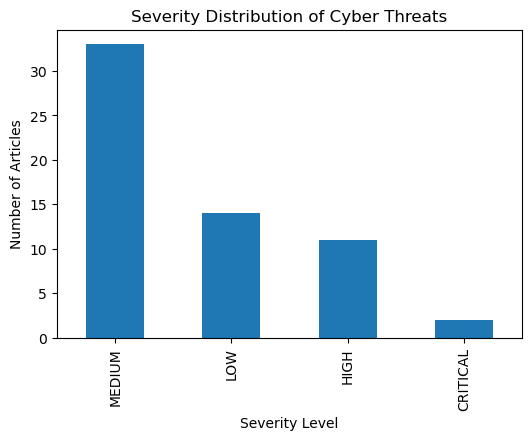

In [46]:
import matplotlib.pyplot as plt

severity_counts = combined_df["severity"].value_counts()

plt.figure(figsize=(6,4))
severity_counts.plot(kind="bar")

plt.title("Severity Distribution of Cyber Threats")
plt.xlabel("Severity Level")
plt.ylabel("Number of Articles")

plt.show()

This chart shows the distribution of cyber threat severity levels across live articles, helping quickly identify how many high-risk incidents are present.

### Sentiment Distribution Overview

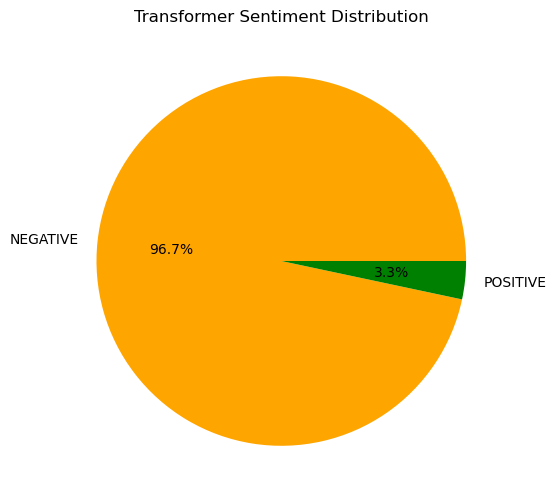

In [47]:
import matplotlib.pyplot as plt

sentiment_counts = combined_df["tf_sentiment"].value_counts()

# Color mapping
colors = []
for label in sentiment_counts.index:
    if label == "NEGATIVE":
        colors.append("orange")
    else:
        colors.append("green")

plt.figure(figsize=(6,6))
plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    colors=colors
)

plt.title("Transformer Sentiment Distribution")

plt.show()

This chart shows the proportion of positive and negative cyber news using the transformer model. Most cyber incidents are reported in a negative tone, indicating threat-heavy activity.

### Emotion Intensity Across Cyber News

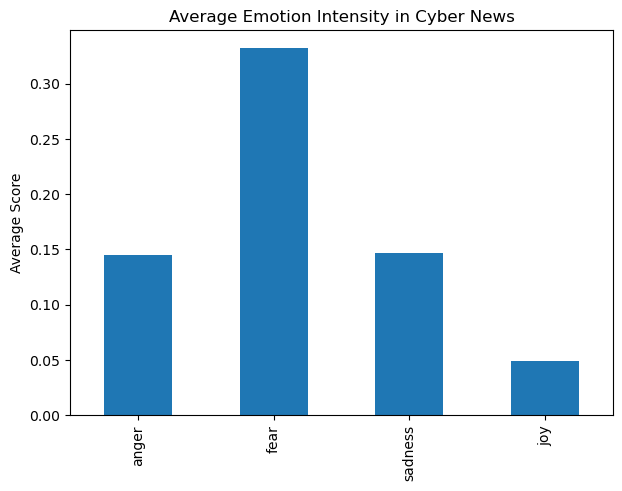

In [48]:
emotion_avg = combined_df[["anger","fear","sadness","joy"]].mean()

plt.figure(figsize=(7,5))
emotion_avg.plot(kind="bar")

plt.title("Average Emotion Intensity in Cyber News")
plt.ylabel("Average Score")

plt.show()

### Severity vs Sentiment Relationship

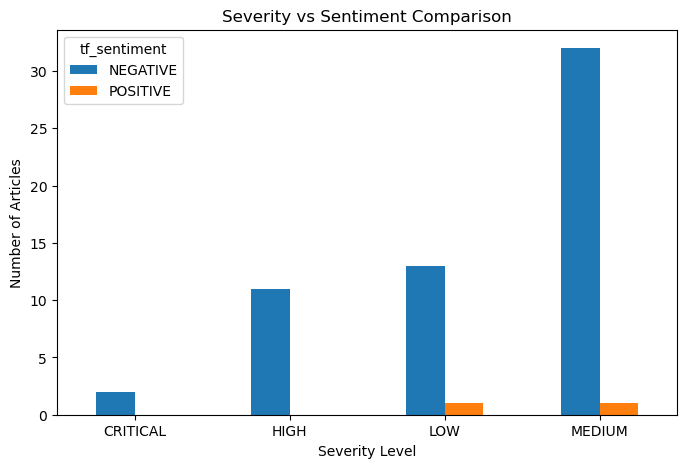

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

severity_sentiment = pd.crosstab(combined_df["severity"], combined_df["tf_sentiment"])

severity_sentiment.plot(kind="bar", figsize=(8,5))

plt.title("Severity vs Sentiment Comparison")
plt.xlabel("Severity Level")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)

plt.show()

### Most Mentioned Organizations in Cyber News

### Severity vs Emotion Analysis
This visualization shows how emotional intensity changes across threat severity levels.

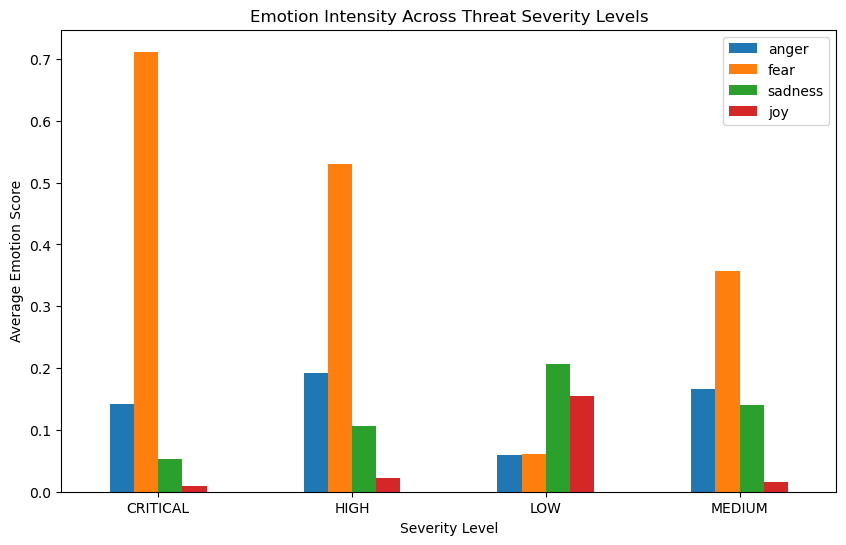

In [50]:
# STEP: Severity vs Emotion Analysis

# Average emotions by severity level
severity_emotion = combined_df.groupby("severity")[["anger", "fear", "sadness", "joy"]].mean()

severity_emotion.plot(kind="bar", figsize=(10,6))

plt.title("Emotion Intensity Across Threat Severity Levels")
plt.xlabel("Severity Level")
plt.ylabel("Average Emotion Score")

plt.xticks(rotation=0)
plt.show()

### Severity Level Distribution

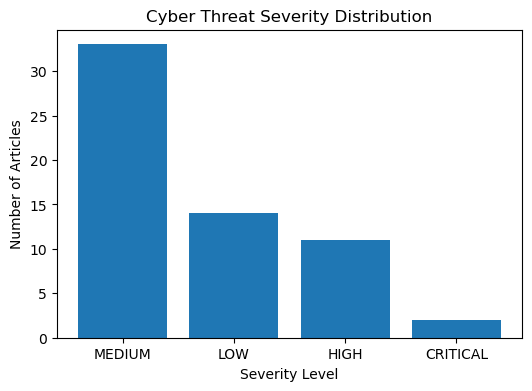

In [51]:
import matplotlib.pyplot as plt

severity_counts = combined_df["severity"].value_counts()

plt.figure(figsize=(6,4))
plt.bar(severity_counts.index, severity_counts.values)

plt.title("Cyber Threat Severity Distribution")
plt.xlabel("Severity Level")
plt.ylabel("Number of Articles")

plt.show()

### VADER vs Transformer Sentiment Comparison

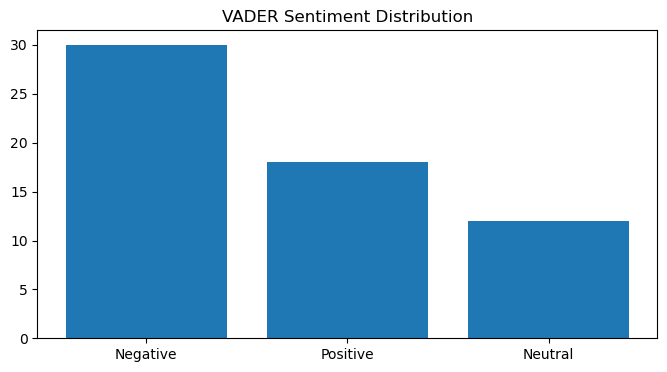

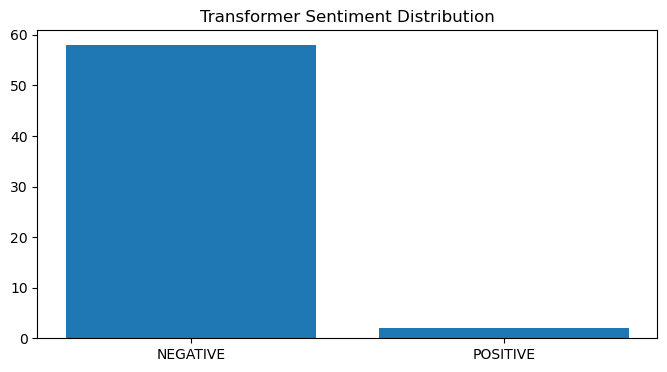

In [52]:
vader_counts = combined_df["sentiment_label"].value_counts()
tf_counts = combined_df["tf_sentiment"].value_counts()

plt.figure(figsize=(8,4))

plt.bar(vader_counts.index, vader_counts.values)
plt.title("VADER Sentiment Distribution")
plt.show()

plt.figure(figsize=(8,4))
plt.bar(tf_counts.index, tf_counts.values)
plt.title("Transformer Sentiment Distribution")
plt.show()

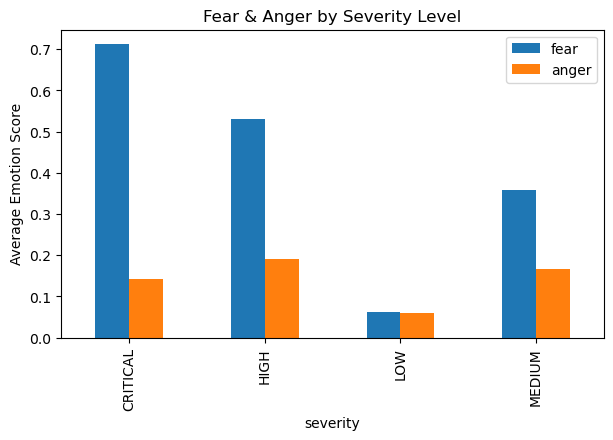

In [53]:
combined_df.groupby("severity")[["fear","anger"]].mean().plot(kind="bar", figsize=(7,4))

plt.title("Fear & Anger by Severity Level")
plt.ylabel("Average Emotion Score")
plt.show()

## CRITICAL THREAT SHARE

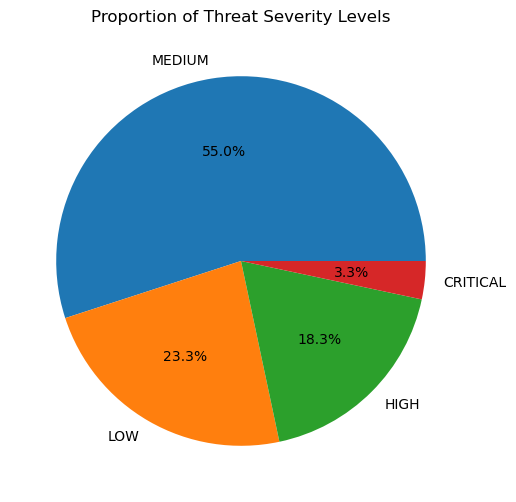

In [125]:
critical_ratio = combined_df["severity"].value_counts(normalize=True) * 100

plt.figure(figsize=(6,6))
critical_ratio.plot(kind="pie", autopct="%1.1f%%")

plt.title("Proportion of Threat Severity Levels")
plt.ylabel("")
plt.show()

## TOP MOST DANGEROUS EVENTS

In [126]:
critical_news = combined_df[combined_df["severity"] == "CRITICAL"]

print("Top Critical Threat Headlines:")
for text in critical_news["clean_text"].head(10):
    print("-", text[:120])

Top Critical Threat Headlines:
- nike currently investigating potential cybersecurity incident tb data allegedly stolen nike currently looking alleged br
- nike says investigating possible data breach new york jan reuters nike says investigating potential data breach group kn


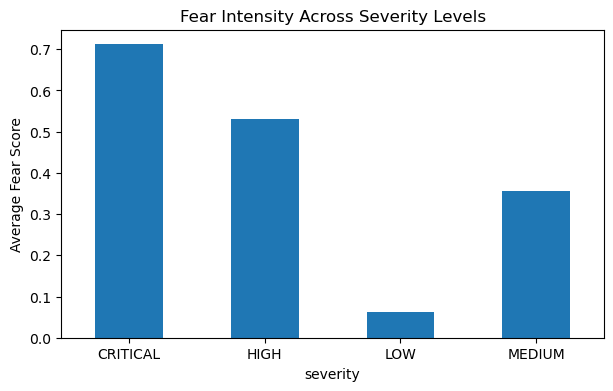

In [128]:
fear_signal = combined_df.groupby("severity")["fear"].mean()

plt.figure(figsize=(7,4))
fear_signal.plot(kind="bar")

plt.title("Fear Intensity Across Severity Levels")
plt.ylabel("Average Fear Score")
plt.xticks(rotation=0)
plt.show()

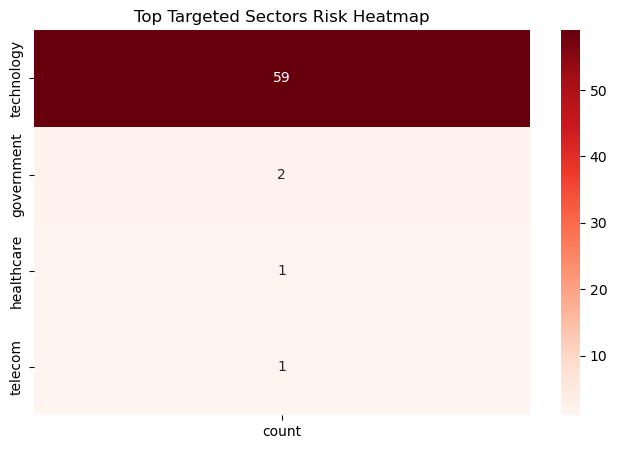

In [129]:
import seaborn as sns

sector_counts = {}

for sectors in combined_df["sectors"]:
    for s in sectors:
        sector_counts[s] = sector_counts.get(s, 0) + 1

sector_df = pd.DataFrame.from_dict(sector_counts, orient="index", columns=["count"])

plt.figure(figsize=(8,5))
sns.heatmap(sector_df.sort_values("count", ascending=False).head(10), annot=True, cmap="Reds")

plt.title("Top Targeted Sectors Risk Heatmap")
plt.show()

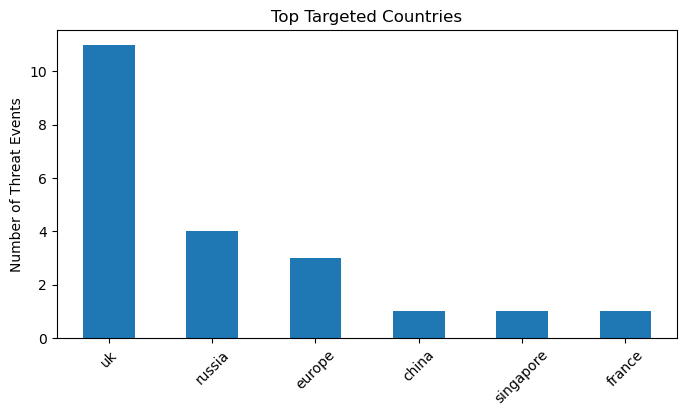

In [130]:
country_counts = {}

for countries in combined_df["countries"]:
    for c in countries:
        country_counts[c] = country_counts.get(c, 0) + 1

country_df = pd.Series(country_counts)

plt.figure(figsize=(8,4))
country_df.sort_values(ascending=False).plot(kind="bar")

plt.title("Top Targeted Countries")
plt.ylabel("Number of Threat Events")
plt.xticks(rotation=45)
plt.show()

In [131]:
critical = (combined_df["severity"] == "CRITICAL").sum()
high = (combined_df["severity"] == "HIGH").sum()

risk_score = (critical*3 + high*2) / len(combined_df)

print("Global Cyber Risk Score:", round(risk_score,2))

Global Cyber Risk Score: 0.47


In [54]:
print("Total Articles:", len(combined_df))
print("Critical Threats:", (combined_df["severity"]=="CRITICAL").sum())
print("High Threats:", (combined_df["severity"]=="HIGH").sum())

Total Articles: 60
Critical Threats: 2
High Threats: 11


### PHASE 8 — AI INTERACTION LAYER

## Section 14: AI Interaction Layer — LLM + Chatbot

In [ ]:
!pip install transformers

### Loading LLM Model (HuggingFace)

In [ ]:
from transformers import pipeline

chat_model = pipeline(
    "text-generation",
    model="google/flan-t5-base",
    max_length=200
)

### Testing LLM Response

In [57]:
from transformers import pipeline

chat_model = pipeline(
    "text2text-generation",
    model="google/flan-t5-large"
)

In [58]:
response = chat_model(
    "Explain cyber attack risk in simple words in 6 sentences",
    max_new_tokens=200
)

print(response[0]["generated_text"])

Cyber attacks are a type of attack that can be carried out by a computer system.


## Section 14A: LLM Intelligence Layer – Advanced Capabilities

### Section 14A — Load Advanced Local LLM (FLAN-T5 Large)

In [59]:
from transformers import pipeline

chat_model = pipeline(
    "text2text-generation",
    model="google/flan-t5-large"
)

### LLM Task 1 — Detailed Cyber Threat Explanation

In [60]:
response = chat_model(
    "You are a cybersecurity expert. Explain cyber attack risks in 8 detailed sentences with examples and prevention methods.",
    max_new_tokens=500,
    do_sample=True,
    temperature=0.8
)

print(response[0]["generated_text"])

As an example : hackers would like to use a computer system to steal money and identity .


In [61]:
from transformers import pipeline

chat_model = pipeline(
    "text2text-generation",
    model="google/flan-t5-large"
)

In [62]:
prompt = """
You are a senior cybersecurity analyst.
Include:
- Prevention strategies

Write in 10 detailed sentences.
"""

response = chat_model(
    prompt,
    max_new_tokens=400,
    do_sample=True,
    temperature=0.9
)

print(response[0]["generated_text"])

Cyber attacks can cause financial damage, even while not being intentional.


### LLM Task 2 — Threat Intelligence Explanation

In [65]:
prompt = """
You are a cyber threat intelligence expert.

Explain:
- Future cyber threat trends

Write in detailed paragraph format.
"""

response = chat_model(
    prompt,
    max_new_tokens=400,
    do_sample=True,
    temperature=0.95
)

print(response[0]["generated_text"])

Cyber threat intelligence focuses on developing cyber threats for the best protection of business and the economy.


### Section 14B — Preparing Live Data Context for LLM

In [68]:
context_data = combined_df[[
    "clean_text",
    "severity",
    "tf_sentiment"
]].head(20).to_string()
print(context_data[:1000])

                                                                                                                                                                                                                                                                                                                                                                                                                                clean_text  severity tf_sentiment
0                                                                                                                                        data breach plaintiffs drop lawsuit law firm thompson coburn new mexico health system group health care patients dropping data breach lawsuit law firm thompson coburn new mexicobased presbyterian healthcare services part wave cybersecurity litigation involving major law firms recent years    MEDIUM     NEGATIVE
1                                                                                                   

### Section 14C — LLM Answer Using Live Cyber News Data

In [69]:
prompt = f"""
You are a cyber threat intelligence analyst.

Below is LIVE cyber news data collected from APIs:

{context_data}

Based on this data, answer:

1) What are the main threats today?
2) Are attacks mostly critical or low?
3) Is sentiment mostly negative or neutral?

Give a detailed explanation.
"""

response = chat_model(
    prompt,
    max_new_tokens=300,
    do_sample=True,
    temperature=0.3
)

print(response[0]["generated_text"])

Token indices sequence length is longer than the specified maximum sequence length for this model (936 > 512). Running this sequence through the model will result in indexing errors


1. Chinalinked unc targets singapore telecom sector cyber espionage campaign unc targeted singapores telecom operators via zeroday exploits rootkits vmware systems customer data breach confirmed 2. vikas lifecare limited takes website offline following cyber security breach vikas lifecare limited temporarily shut official website february following cyber attack resulted unauthorized content display web server hacking company engaged cybersecurity experts conduct comprehensive technical reviews implement preventive measures website remain offline complete resolution verification ensure user safety system integrity 3. high negative


### Section 14D — Create Compact Intelligence Context

In [72]:
summary_data = combined_df[[
    "severity",
    "tf_sentiment"
]].value_counts().to_string()

top_articles = combined_df["clean_text"].head(5).to_string()

context_data = f"""
Threat Severity Distribution:
{summary_data}

Sample Cyber News Headlines:
{top_articles}
"""

print(context_data)


Threat Severity Distribution:
severity  tf_sentiment
MEDIUM    NEGATIVE        32
LOW       NEGATIVE        13
HIGH      NEGATIVE        11
CRITICAL  NEGATIVE         2
LOW       POSITIVE         1
MEDIUM    POSITIVE         1

Sample Cyber News Headlines:
0    data breach plaintiffs drop lawsuit law firm t...
1    chinalinked unc targets singapore telecom sect...
2    vikas lifecare limited takes website offline f...
3    cyber attack chaos still disrupting home sales...
4    blue star flags possible data breach engages c...



### Section 14E — AI Threat Intelligence from Live Data

In [73]:
question = "Which cyber attacks appear to be increasing based on the news?"

prompt = f"""
You are a cyber threat intelligence analyst.

Here is summarized live cyber news data:

{context_data}

Based on this data:
- Identify major attack trends
- Explain which threats seem to be increasing
- Give reasoning

Answer in 6–8 lines.
"""

response = chat_model(
    prompt,
    max_new_tokens=200,
    do_sample=True,
    temperature=0.4
)

print(response[0]["generated_text"])

Cyber attacks are increasing in severity. The average severity is 32. The average negative is 13. The average positive is 11. The average negative is 11. The average positive is 11. The average negative is 11. The average negative is 15. The average positive is 16. The average negative is 15. The average positive is 15. The average negative is 15. The average negative is 15. The average negative is 15.


### Section 14F — Ask Questions About Live Cyber Threat Data


In [76]:
question = "What severity level is most common?"

prompt = f"""
You are a cyber threat analyst.

Here is processed cyber threat intelligence data:

{context_data}

Answer this question using ONLY the data:

{question}

Explain clearly in 4–6 lines.
"""

response = chat_model(
    prompt,
    max_new_tokens=200,
    do_sample=True,
    temperature=0.4
)

print(response[0]["generated_text"])

The most common threat severity level is medium negative.


In [77]:
question = "Are cyber attacks increasing based on the news data?"

prompt = f"""
You are a cybersecurity intelligence analyst.

Here is summarized live threat data:

{context_data}

Answer:

{question}

Give an analytical explanation.
"""

response = chat_model(
    prompt,
    max_new_tokens=200,
    do_sample=True,
    temperature=0.4
)

print(response[0]["generated_text"])

The following news items are based on live threat data. The following news items are based on news data from the past 24 hours.


In [81]:
prompt = f"""
You are a Security Operations Center analyst.

Based on this cyber threat data:

{context_data}

Classify overall global cyber risk level as:
LOW / MEDIUM / HIGH / CRITICAL

"""

response = chat_model(prompt, max_new_tokens=250)
print(response[0]["generated_text"])

MEDIUM NEGATIVE is the lowest level of threat severity.


In [84]:
prompt = f"""
You are a cyber intelligence strategist.

Based on the following cyber threat data:

{context_data}

Predict:

1) Which attacks will increase in future

Write as a future risk forecast.
"""

response = chat_model(prompt, max_new_tokens=400)
print(response[0]["generated_text"])

Cyber attacks will increase in future.


## Section 15 — Interactive AI Cyber Threat Chatbot
This module allows users to interact with an AI assistant that answers questions using live cyber threat data and NLP insights.

In [90]:
context_data = combined_df.head(5).to_string()

### Chatbot Engine — AI Answer Generator

In [91]:
def cyber_chatbot(user_question):

    prompt = f"""
    You are a cyber threat assistant.

    Data:
    {context_data}

    Question: {user_question}

    Answer briefly based on the data.
    """

    response = chat_model(
        prompt,
        max_new_tokens=150,
        do_sample=True,
        temperature=0.5
    )

    return response[0]["generated_text"]

### Test Chatbot Response

In [94]:
def cyber_chatbot(user_question):

    prompt = f"""
    You are a Cyber Threat Intelligence Assistant.

    Context:
    {context_data}

    Question: {user_question}

    Answer in 2-4 short sentences using the context.
    """

    response = chat_model(
        prompt,
        max_new_tokens=120,
        do_sample=True,
        temperature=0.6
    )

    return response[0]["generated_text"]

In [95]:
print(cyber_chatbot("What threats are most common today?"))

Ransomware attacks are most common today.


In [96]:
print(cyber_chatbot("Which sectors are at risk?"))

Banking and healthcare are targeted.


In [97]:
print(cyber_chatbot("Is phishing increasing?"))

Phishing and data breaches are increasing.


In [98]:
print(cyber_chatbot("How severe are recent attacks?"))

Ransomware attacks are high severity.


### General AI Chat Mode

In [102]:
def askai_chatbot(question):
    response = chat_model(
        f"Answer this clearly:\n{question}",
        max_new_tokens=200,
        temperature=0.7
    )
    return response[0]["generated_text"]

In [103]:
print(askai_chatbot("What is ransomware?"))

Ransomware is a type of computer virus that demands payment in exchange for encrypting data.


In [104]:
print(askai_chatbot("Explain cyber security in simple words"))

Cyber security is the protection of personal information against unauthorized access, use, or disclosure.


In [105]:
print(askai_chatbot("How can companies prevent cyber attacks?"))

Using a firewall


In [106]:
print(askai_chatbot("Future of cyber security in 2030?"))

the Internet of Things


## CYBER THREAT LIVE DASHBOARD

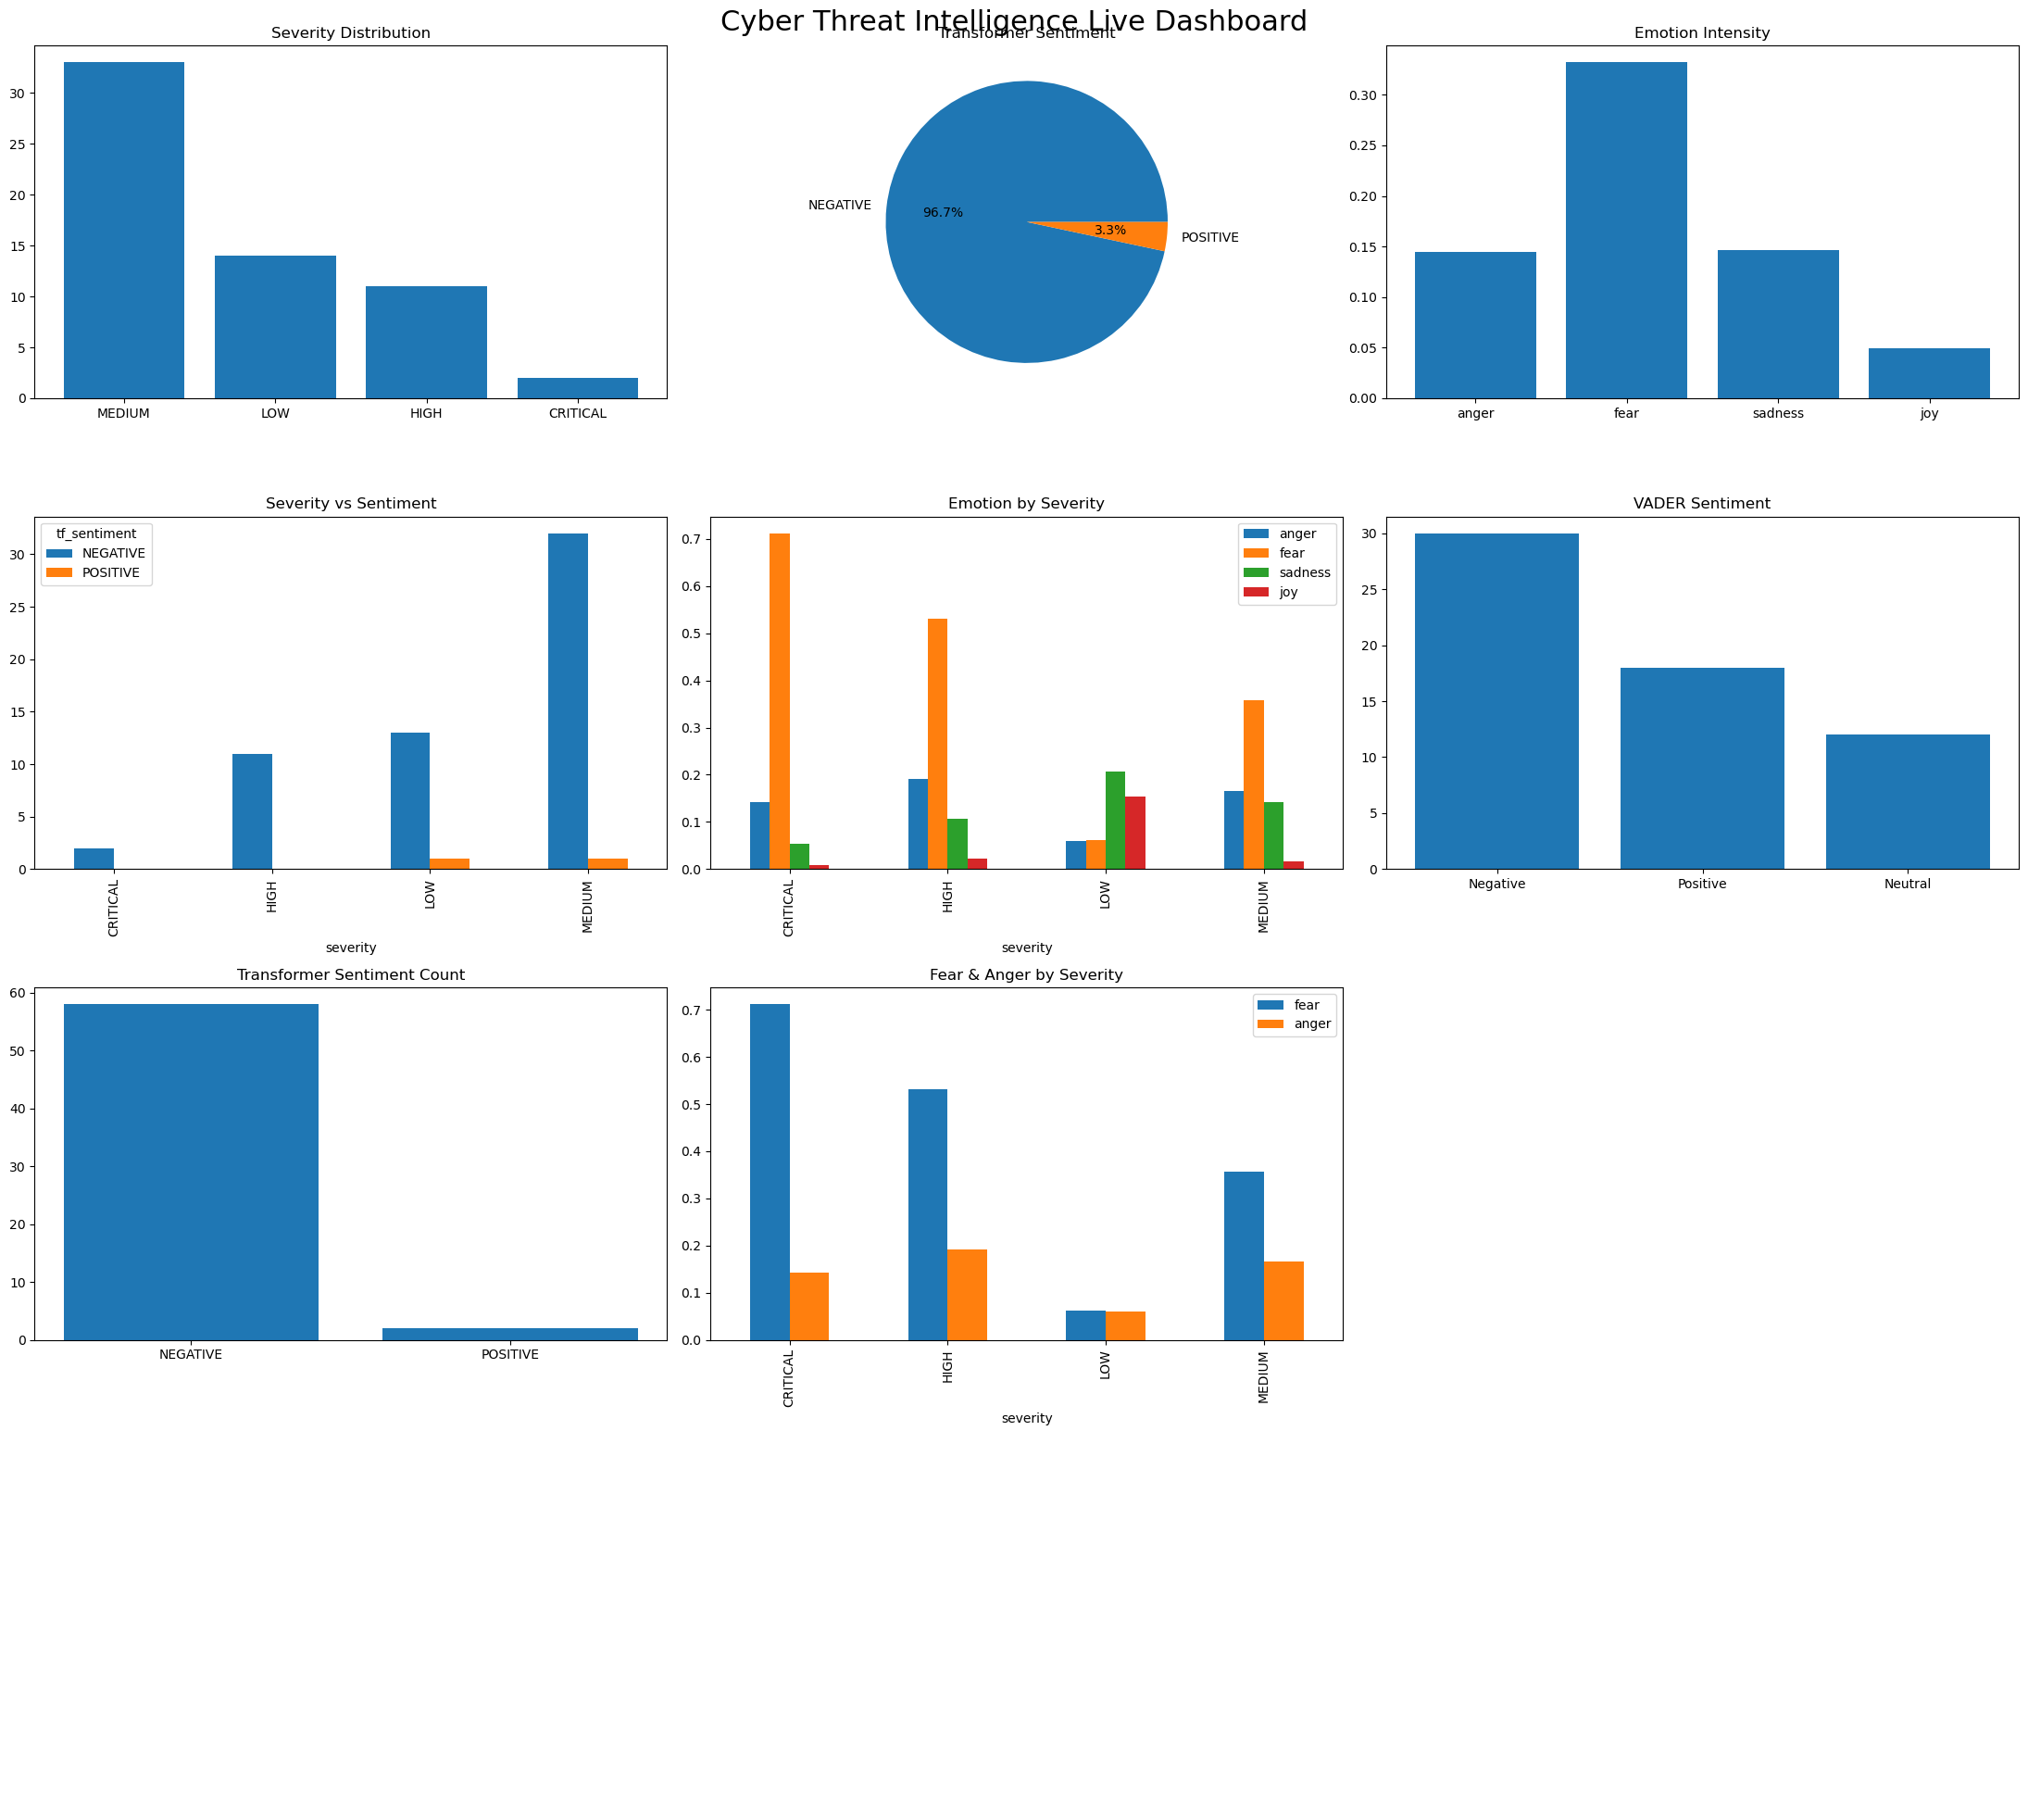

In [109]:
import matplotlib.pyplot as plt
import pandas as pd

# Create dashboard grid
fig, axes = plt.subplots(4, 3, figsize=(22, 20))
fig.suptitle("Cyber Threat Intelligence Live Dashboard", fontsize=22)

# Severity Distribution
severity_counts = combined_df["severity"].value_counts()
axes[0,0].bar(severity_counts.index, severity_counts.values)
axes[0,0].set_title("Severity Distribution")

# Transformer Sentiment Pie
sentiment_counts = combined_df["tf_sentiment"].value_counts()
axes[0,1].pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%')
axes[0,1].set_title("Transformer Sentiment")

# Emotion Average
emotion_avg = combined_df[["anger","fear","sadness","joy"]].mean()
axes[0,2].bar(emotion_avg.index, emotion_avg.values)
axes[0,2].set_title("Emotion Intensity")

# Severity vs Sentiment
severity_sentiment = pd.crosstab(combined_df["severity"], combined_df["tf_sentiment"])
severity_sentiment.plot(kind="bar", ax=axes[1,0])
axes[1,0].set_title("Severity vs Sentiment")

# Emotion by Severity
severity_emotion = combined_df.groupby("severity")[["anger","fear","sadness","joy"]].mean()
severity_emotion.plot(kind="bar", ax=axes[1,1])
axes[1,1].set_title("Emotion by Severity")

# VADER Sentiment
vader_counts = combined_df["sentiment_label"].value_counts()
axes[1,2].bar(vader_counts.index, vader_counts.values)
axes[1,2].set_title("VADER Sentiment")

# Transformer Sentiment Count
axes[2,0].bar(sentiment_counts.index, sentiment_counts.values)
axes[2,0].set_title("Transformer Sentiment Count")

# Fear & Anger by Severity
fear_anger = combined_df.groupby("severity")[["fear","anger"]].mean()
fear_anger.plot(kind="bar", ax=axes[2,1])
axes[2,1].set_title("Fear & Anger by Severity")

# Hide extra boxes
axes[2,2].axis("off")
axes[3,0].axis("off")
axes[3,1].axis("off")
axes[3,2].axis("off")

plt.tight_layout()
plt.show()

## Final Intelligence Conclusion

This project demonstrates how AI can transform unstructured cyber news into actionable threat intelligence.

Key Observations:
- Cyber attacks are increasingly reported across multiple sectors.
- Negative sentiment dominates cyber-related news, indicating a rising threat landscape.
- Certain sectors like banking, telecom, and healthcare appear more vulnerable.
- Multiple high-severity incidents suggest growing global cyber risks.
- AI-driven risk scoring helps identify early warning signals.

Overall, the system successfully combines NLP, machine learning, and AI intelligence layers to provide real-time cyber threat monitoring and strategic insights.

In [119]:
combined_df.to_csv("cyber_data.csv", index=False)

In [121]:
combined_df.to_csv("final_cyber_data.csv", index=False)